<a href="https://colab.research.google.com/github/ginajuliana/EPR_08/blob/main/gpu_cpu_vergleich.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# QR und SVD - Zerlegung auf GPR und CPU

# Histogramm: sinnvolle Reihenfolge
# Befehl, um CPU abzufragen - vergleichbarkeit und unterschiedliche laufzeiten erklären -> random zahl, aber die fix halten
# SVD driver auswählen - thema: reduced matrix
# -> wie schneiden die untersch. ab : gesvdj’ and, if it fails, we fallback to ‘gesvd’.: noch ein balken
# datentransfer noch ein balken
# floats und double vergleichen

# Anmerkungen
# reduzierte Matrix bei "SVD auf GPU ausführen"??
# bei QR: mode = "reduced"
# bei SVD: full_matrices=False
# Gesamt: funktion mit , cpu/gpu, datentransfer ja/nein, reduced ja/nein, default driver None JA/nein, svd/qr, matrix werte
# 128x128, 8196x8196, 128x32, 64000x??
# pseudo zufallsmatrix = torch.Generator().manual_seed(x)
# torch.randn(n, m, generator = zufallsmatrix)
#manche Blöcke auf cpu, andere auf gpu laufen lassen?


# Anmerkungen
# Warm-Up?
# Datentransfer messen?
# - Was, wenn Daten wieder zurück auf die CPU sollen?
# "kopieren" - Schritt also mit in die Messung nehmen?
# Aber wo wäre der "zurück-kopieren"-Schritt?
# Reduced Matrix benutzen?

torch.cuda.is_available()

True

In [2]:
### Nochmal von neu

import torch
import time
import matplotlib.pyplot as plt

# Funktion 01
# Matrix erstellen

def create_matrix(m, n, dtype, seed):

    # Generator mit festem Seed erstellen
    generator = torch.Generator().manual_seed(seed)


    matrix = torch.randn(m, n, dtype=dtype, generator=generator)

    return matrix

    # Fragen
    # was macht seed 42

In [4]:
# Funktion 02
# Funktion für SVD- und QR-Zerlegung auf der CPU


# matrix wird oben erstellt
# method ist qr oder svd
# reduced ist True oder False

def cpu_decomposition(matrix, method, reduced):

    # Leere Liste für die gemessenen Zeiten
    list_of_times = []

    # Zerlegung elfmal ausführen
    # Erster Durchlauf dient als Warm-up
    for i in range(11):

        # Zeitmessung starten
        start = time.perf_counter()

        # Gewünschte Zerlegung ausführen
        if method == "svd":

            U, S, Vh = torch.linalg.svd(
                matrix, full_matrices=not reduced
            )

        elif method == "qr":

            if reduced == True:
                Q, R = torch.linalg.qr(matrix, mode="reduced")

            else:
                Q, R = torch.linalg.qr(matrix, mode="complete")

        # Zeitmessung stoppen
        end = time.perf_counter()

        # Zeit berechnen
        duration = end - start

        # Warm-up nicht speichern
        if i > 0:
            list_of_times.append(duration)

    # Durchschnitt bilden
    average = sum(list_of_times) / len(list_of_times)

    # In Millisekunden umrechnen
    average_ms = average * 1000

    # Ergebnisse ausgeben
    print(method.upper(), "CPU - Alle Messungen:", list_of_times)
    print(method.upper(), "CPU - Durchschnitt:", average_ms, "ms")

    # Später eventuell zusätzlich den Median berechnen

    return average_ms


In [5]:

# Funktion 03
# Funktion für SVD- und QR-Zerlegung auf der GPU

# gpu_decomposition() gibt bei nicht verfügbarer CUDA-GPU aktuell
# None zurück. Deshalb sollte unsere spätere Testfunktion solche
# Ergebnisse überspringen, statt zu versuchen,
# sie als Balken darzustellen


# matrix ist oben erstellt
# method ist qr oder svd
# reduced ist True oder False
# include_transfer ist True oder False
# driver ist None oder gesvdj oder gesvd oder gesvda

def gpu_decomposition(matrix, method, reduced, include_transfer, driver=None):

    # Prüfen, ob CUDA-GPU verfügbar ist
    if torch.cuda.is_available() == False:
        print("Keine CUDA-GPU verfügbar")
        return

    # Matrix vor der Messung auf GPU kopieren
    if include_transfer == False:
        matrix_gpu = matrix.to("cuda")

    # Leere Liste für GPU-Messzeiten erstellen
    list_of_times = []

    # Zerlegung elfmal ausführen
    # Erster Durchlauf dient als Warm-up
    for i in range(11):

        # Warten, bis vorherige GPU-Berechnungen fertig sind
        torch.cuda.synchronize()

        # Zeitmessung starten
        start = time.perf_counter()

        # Datentransfer gegebenenfalls mitmessen
        if include_transfer == True:
            matrix_gpu = matrix.to("cuda")

        # Gewünschte Zerlegung ausführen
        if method == "svd":

            U, S, Vh = torch.linalg.svd(
                matrix_gpu,
                full_matrices=not reduced,
                driver=driver
            )

        elif method == "qr":

            if reduced == True:
                Q, R = torch.linalg.qr(matrix_gpu, mode="reduced")

            else:
                Q, R = torch.linalg.qr(matrix_gpu, mode="complete")

        # Warten, bis die GPU fertig gerechnet hat
        torch.cuda.synchronize()

        # Zeitmessung stoppen
        end = time.perf_counter()

        # Zeit berechnen
        duration = end - start

        # Warm-up nicht speichern
        if i > 0:
            list_of_times.append(duration)

    # Durchschnitt bilden
    average = sum(list_of_times) / len(list_of_times)

    # In Millisekunden umrechnen
    average_ms = average * 1000

    # Ergebnisse ausgeben
    print("GPU - Datentyp:", matrix.dtype)
    print(method.upper(), "GPU - Alle Messungen:", list_of_times)
    print(method.upper(), "GPU - Durchschnitt:", average_ms, "ms")

    # Später eventuell zusätzlich den Median berechnen

    return average_ms




In [6]:
# Funktion 04
# Überfunktion für die Laufzeitmessung

def measure_runtime(m, n, dtype, method, device,
                    reduced=True, include_transfer=False,
                    driver=None, seed=42):

    # Matrix erstellen
    matrix = create_matrix(m, n, dtype, seed)

    # CPU-Zerlegung
    if device == "cpu":

        runtime = cpu_decomposition(matrix, method, reduced)

    # GPU-Zerlegung
    elif device == "cuda":

        runtime = gpu_decomposition(
            matrix,
            method,
            reduced,
            include_transfer,
            driver
        )

    else:
        print("Ungültiges Gerät")
        return

    # Durchschnittliche Laufzeit zurückgeben
    return runtime

In [ ]:
# Überspringen!!!
# Funktion 05
# vergleicht 8 Kombinationen: SVD/QR, CPU/GPU, float/double
# Reduced fehlt noch und verschiedene Matrizen und Datentransfer
# Zum Testen und Vergleichen der Werte

# Wir haben 48 Kombinationsmöglichkeiten, die die Testfunktion alle automatisch durchlaufen soll
# Die Ergebnisse sollen in Tabellen(?) und Histogrammen dargestellt werden - schlau anordnen

def compare_runtimes():

    # Leere Listen für die Ergebnisse erstellen
    names = []
    times = []

    # Verfügbare Geräte
    devices = ["cpu"]

    # Prüfen, ob CUDA-GPU verfügbar ist
    if torch.cuda.is_available():
        devices.append("cuda")

    # SVD und QR
    for method in ["svd", "qr"]:

        # Float32 und Float64
        for dtype in [torch.float32, torch.float64]:

            # CPU und GPU
            for device in devices: # for device in ["cpu", "cuda"]

                # Laufzeit messen
                runtime = measure_runtime(
                    m=1000,
                    n=1000,
                    dtype=dtype,
                    method=method,
                    device=device,
                    reduced=True
                )

                # Ergebnisse in Listen speichern
                names.append(method.upper() + " " + device.upper() + " " + str(dtype))
                times.append(runtime)

    # Balkendiagramm erstellen
    plt.figure(figsize=(12, 6)) # Wofür figsize?????
    plt.bar(names, times)

    # Diagramm beschriften
    plt.title("Laufzeitvergleich von SVD und QR")
    plt.xlabel("Berechnung")
    plt.ylabel("Laufzeit in Millisekunden")

    # Beschriftungen drehen
    plt.xticks(rotation=45, ha="right") # Wieso Beschriftung drehen und wie funktioniert
                                        # dieser Befehl überhaupt?????

    # Diagramm anzeigen
    plt.tight_layout() # Wofür ist dieser Befehl????
    plt.show()


# Funktion aufrufen
compare_runtimes()


In [7]:
# Funktion 07
# Funktionen für die verschiedenen Matrixgrößen

# Quadratische
def square_matrices():

    # Leere Liste für Matrixgrößen-Tupel
    sizes = []

    # Verschiedene Matrixgrößen
    for size in [100, 250, 500, 1000, 2000]:

        # Matrixgröße in Liste speichern
        sizes.append((size, size))

    return sizes


# Funktion testen
print(square_matrices())

#####################################################

# Hohe und Schmale
def tall_matrices():

    # Leere Liste für Matrixgrößen erstellen
    sizes = []

    # Anzahl der Zeilen verändern
    for m in [250, 500, 1000, 2000, 4000]:

        # Anzahl der Spalten bleibt gleich
        n = 100

        # Matrixgröße in Liste speichern
        sizes.append((m, n))

    return sizes


# Funktion testen
print(tall_matrices())

#######################################################

# Breite und Flache
def wide_matrices():

    # Leere Liste für Matrixgrößen erstellen
    sizes = []

    # Anzahl der Spalten verändern
    for n in [250, 500, 1000, 2000, 4000]:

        # Anzahl der Zeilen bleibt gleich
        m = 100

        # Matrixgröße in Liste speichern
        sizes.append((m, n))

    return sizes


# Funktion testen
print(wide_matrices())



[(100, 100), (250, 250), (500, 500), (1000, 1000), (2000, 2000)]
[(250, 100), (500, 100), (1000, 100), (2000, 100), (4000, 100)]
[(100, 250), (100, 500), (100, 1000), (100, 2000), (100, 4000)]


SVD CPU - Alle Messungen: [0.6440560430000062, 0.4511978250000084, 0.4223825169999884, 0.3920273800000018, 0.3953437440000016, 0.4175169360000268, 0.395535093999996, 0.4142307189999883, 0.4197556359999908, 0.4070911400000057]
SVD CPU - Durchschnitt: 435.9137034000014 ms
SVD CPU - Alle Messungen: [0.4227037340000095, 0.39440932799999473, 0.41793390499998395, 0.4020694219999825, 0.3996576339999933, 0.4152963390000082, 0.4009985909999898, 0.4065430520000177, 0.4167391760000214, 0.41222398200000043]
SVD CPU - Durchschnitt: 408.85751630000016 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.3695005309999999, 0.16378334699999186, 0.16369417900000371, 0.16360827200000472, 0.16368009199999278, 0.1633544029999996, 0.1632922259999816, 0.16309632200000124, 0.16330892099998096, 0.16323559100001717]
SVD GPU - Durchschnitt: 184.05538839999736 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.16506938099999502, 0.16334793800001535, 0.16404908499998783, 0.1638295600000106, 0.1

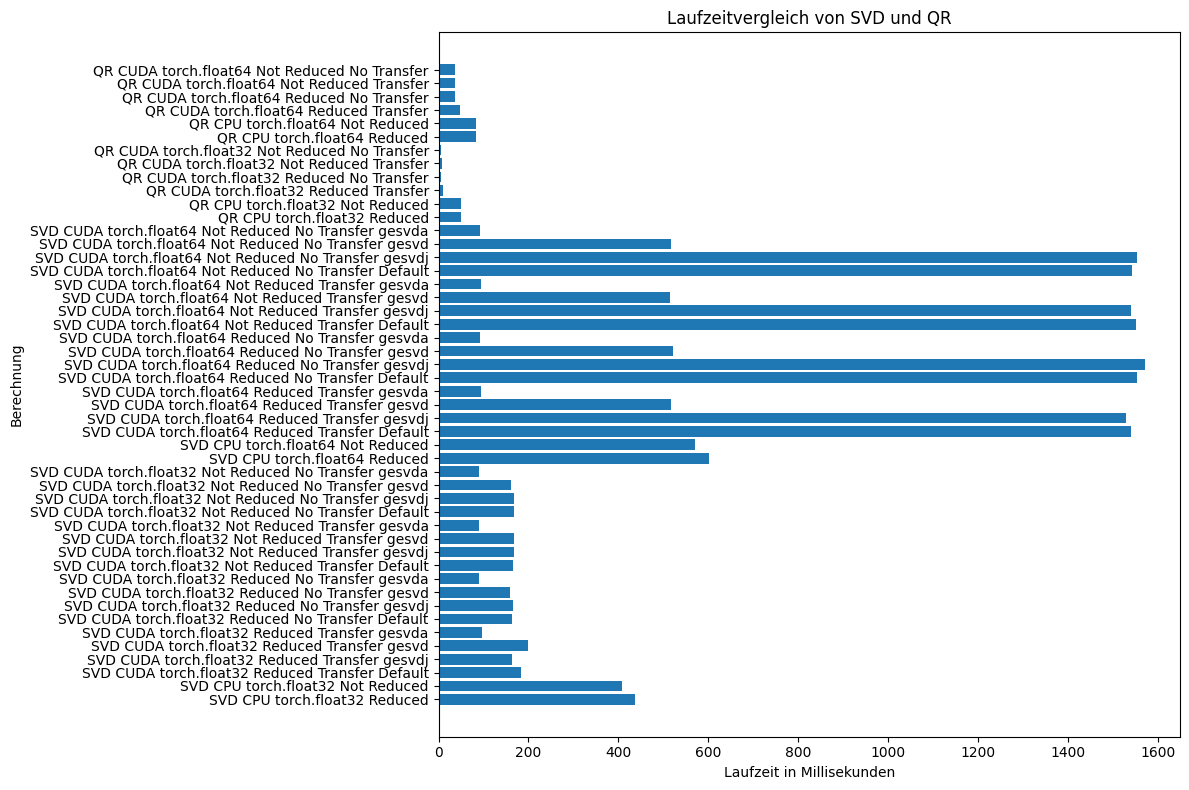

CUDA verfügbar: True


NameError: name 'devices' is not defined

In [ ]:
# Funktion 06
# Überspringen!!

def compare_runtimes(matrix_sizes):

    # Leere Listen für die Ergebnisse
    names = []
    times = []

    # Verfügbare Geräte
    devices = ["cpu"]

    # Prüfen, ob eine CUDA-GPU verfügbar ist
    # ggf "cuda" zu devices Liste hinzufügen
    if torch.cuda.is_available():
        devices.append("cuda")

    for m, n in matrix_sizes:

      # SVD und QR vergleichen
      for method in ["svd", "qr"]:

          # Float32 und Float64 vergleichen
          for dtype in [torch.float32, torch.float64]:

              # CPU und GPU vergleichen
              for device in devices:

                  # Reduzierte und vollständige Zerlegung vergleichen
                  for reduced in [True, False]:

                      # Beschriftung für die Zerlegung für Histogramm später
                      if reduced == True:
                          reduced_name = "Reduced"
                     else:
                          reduced_name = "Not Reduced"

                      # Datentransfer für CPU festlegen
                      transfers = [False]

                      # Bei GPU beide Möglichkeiten vergleichen
                      if device == "cuda":
                          transfers = [True, False]

                      # Mit und ohne Datentransfer vergleichen
                      for include_transfer in transfers:

                          # Standardmäßig keinen speziellen Driver auswählen
                          drivers = [None]

                          # Bei GPU-SVD verschiedene Driver vergleichen
                          if device == "cuda" and method == "svd":
                              drivers = [None, "gesvdj", "gesvd", "gesvda"]

                          # Verschiedene Driver durchlaufen
                          for driver in drivers:

                              # Laufzeit messen
                              runtime = measure_runtime(
                                  m=m,
                                  n=n,
                                  dtype=dtype,
                                  method=method,
                                  device=device,
                                  reduced=reduced,
                                  include_transfer=include_transfer,
                                  driver=driver
                              )

                              # Beschriftung erstellen
                              name = (
                                  method.upper() + " " +
                                  device.upper() + " " +
                                  str(dtype) + " " +
                                  reduced_name
                              )

                              # Datentransfer bei GPU ergänzen
                              if device == "cuda":

                                  if include_transfer == True:
                                      name = name + " Transfer"

                                  else:
                                      name = name + " No Transfer"

                              # Driver bei GPU-SVD ergänzen
                              if device == "cuda" and method == "svd":

                                  if driver == None:
                                      name = name + " Default"

                                  else:
                                      name = name + " " + driver

                              # Ergebnisse in Listen speichern
                              names.append(name)
                              times.append(runtime)

    # Balkendiagramm erstellen
    plt.figure(figsize=(12, 8))
    plt.barh(names, times) #Histogramm um 90 Grad gedreht

    # Diagramm beschriften
    plt.title("Laufzeitvergleich von SVD und QR")
    plt.ylabel("Berechnung")
    plt.xlabel("Laufzeit in Millisekunden")

    # Diagramm anzeigen
    plt.tight_layout()
    plt.show()


# Funktion aufrufen
compare_runtimes(m=1000, n=1000)

print("CUDA verfügbar:", torch.cuda.is_available())
print("Verfügbare Geräte:", devices)


GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.18991118399998186, 0.1641833429999906, 0.16254850800001464, 0.1609244199999864, 0.16224115099998926, 0.16244260999999938, 0.16224449899999627, 0.1623258809999868, 0.1620176590000142, 0.16230616900000427]
SVD GPU - Durchschnitt: 165.11454239999637 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.1626368199999888, 0.16259265299999015, 0.1633706650000022, 0.16334031499999924, 0.16289478100000565, 0.16251447200002644, 0.16298738399999024, 0.16241087399998833, 0.162833954000007, 0.163106627000019]
SVD GPU - Durchschnitt: 162.8688545000017 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.16781113799999048, 0.16798668499998826, 0.1686883010000031, 0.16324609199998008, 0.164084172999992, 0.17084402700001533, 0.16645776300001103, 0.15861841599999593, 0.15851495900000145, 0.15866509300002463]
SVD GPU - Durchschnitt: 164.49166470000023 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.0901563760000101

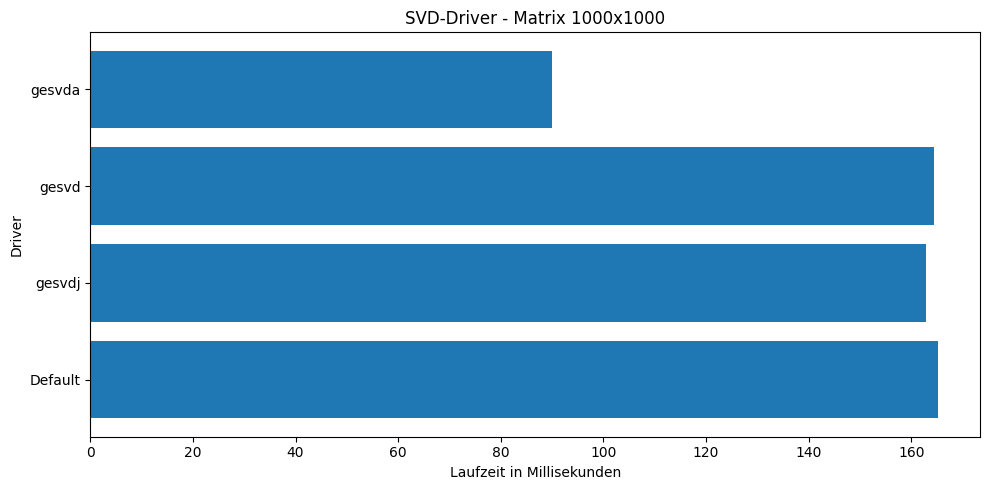

GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.009511037999999417, 0.009446988999997075, 0.009449344000017845, 0.009525890999981357, 0.009449832000001379, 0.009461901000008766, 0.0094970799999885, 0.009498733000015136, 0.009442694000000529, 0.009488848999978927]
SVD GPU - Durchschnitt: 9.477235099998893 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.009528977000002214, 0.009644320999996125, 0.009630042999987154, 0.00965228499998716, 0.009556073999988257, 0.0095408930000076, 0.009496517000002314, 0.00964011000002074, 0.009608086000014282, 0.009488298000007944]
SVD GPU - Durchschnitt: 9.578560400001379 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.01684889599999906, 0.017428828999982215, 0.017269317999989653, 0.019668231999986574, 0.017765761999982033, 0.016797058000008747, 0.01737551399997983, 0.01682398699998089, 0.016938127000003078, 0.01717061200000103]
SVD GPU - Durchschnitt: 17.40863349999131 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle

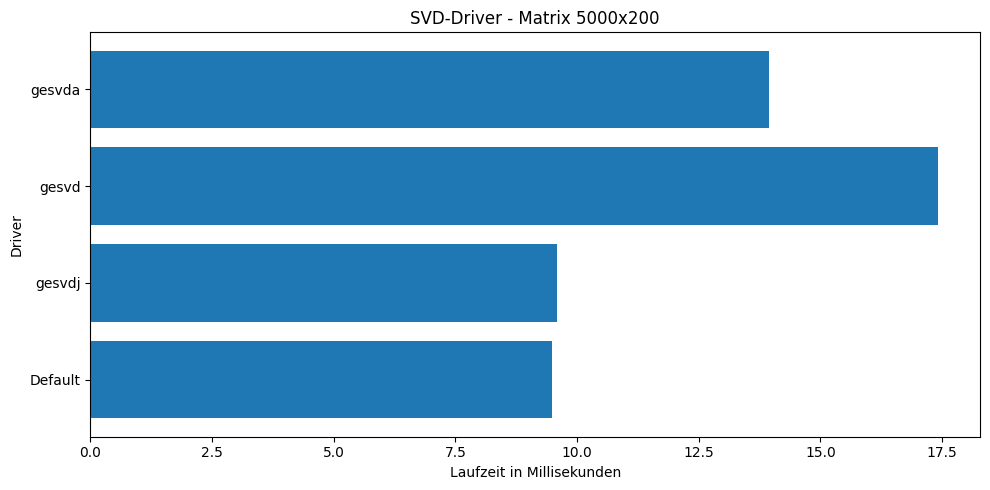

GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.0091334130000007, 0.009120139999993171, 0.009119563000012931, 0.009142109000009668, 0.00914481799998157, 0.009133495999975594, 0.00913267199999268, 0.009136805999986564, 0.009118171000011444, 0.009097906999983252]
SVD GPU - Durchschnitt: 9.127909499994757 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.009124129000014136, 0.009109021000000439, 0.00915716099999031, 0.009173473999993575, 0.009146147999985033, 0.009119763999990482, 0.00916068499998346, 0.00911726300000737, 0.009157641999991029, 0.009157582000000275]
SVD GPU - Durchschnitt: 9.14228689999561 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.01770480499999394, 0.01773666900001558, 0.01769962700001315, 0.01932735900001603, 0.019858240000019123, 0.017264237000006233, 0.017366856999984748, 0.017334832000017286, 0.017379925000000185, 0.017371435000001156]
SVD GPU - Durchschnitt: 17.904398600006743 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle 

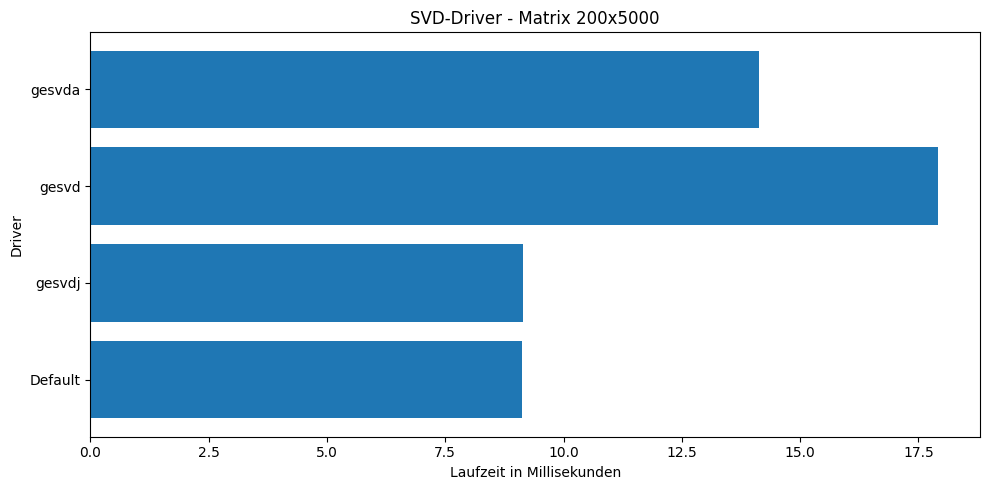

GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.003526805000007016, 0.0035156600000050275, 0.0033327870000050552, 0.003318006999990075, 0.0032956329999933587, 0.0033058459999892875, 0.003324302999999418, 0.003336677000021382, 0.0032897369999886905, 0.0033302050000258987]
SVD GPU - Durchschnitt: 3.357566000002521 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.00342584300000226, 0.003442608000000291, 0.0035994030000097155, 0.0035361380000153986, 0.0033849010000039925, 0.0033568279999940387, 0.0033408310000027086, 0.003315703999987818, 0.003325334000010116, 0.0034087489999876652]
SVD GPU - Durchschnitt: 3.4136339000014004 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.006263119999999844, 0.006202916999995978, 0.0058677469999963705, 0.005947254000005842, 0.005883414000010134, 0.005613400000015645, 0.005687406999982159, 0.006325942000017903, 0.006041910999982747, 0.006104703000005429]
SVD GPU - Durchschnitt: 5.993781500001205 ms
GPU - Datentyp: torch

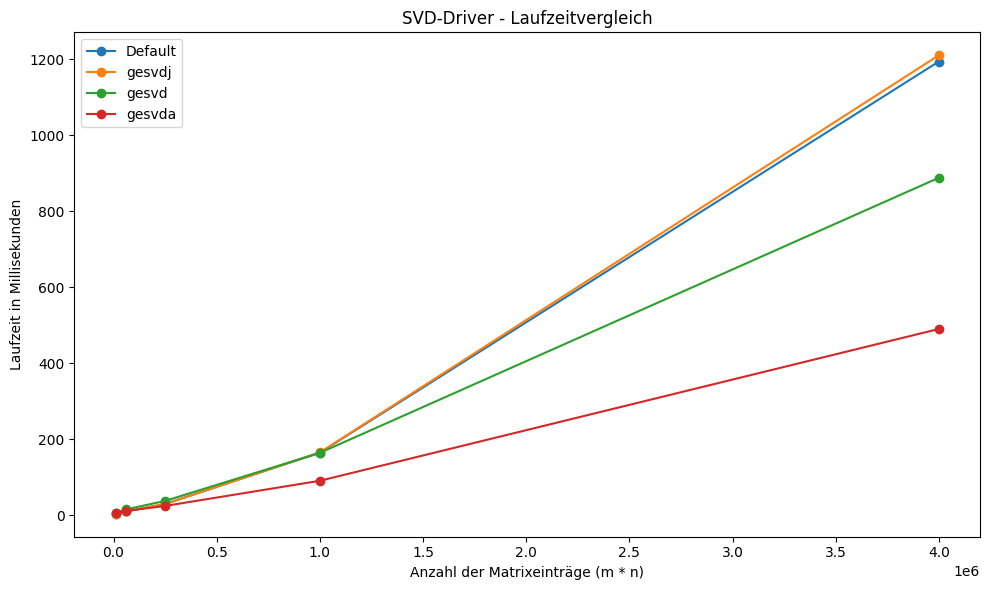

GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.004467895999994198, 0.004233704000000671, 0.004119078999991643, 0.003949726000001874, 0.003914199999996981, 0.003924425999997538, 0.0039011899999934485, 0.0038851499999736916, 0.0039088649999996505, 0.0039055260000111502]
SVD GPU - Durchschnitt: 4.020976199996085 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.003907891000011432, 0.003903834999988476, 0.003912370000023202, 0.0038722230000018953, 0.0038782369999807997, 0.003900243999993336, 0.003908694000017476, 0.0038868699999738965, 0.0038863389999903575, 0.003890701000017316]
SVD GPU - Durchschnitt: 3.8947403999998187 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.00637866900001427, 0.00640607500000101, 0.0067411269999979595, 0.00638933700000166, 0.006313667000000578, 0.006492825000009361, 0.006466762999991715, 0.006378757000021551, 0.006531992000020637, 0.006380083999999897]
SVD GPU - Durchschnitt: 6.447929600005864 ms
GPU - Datentyp: torch.float

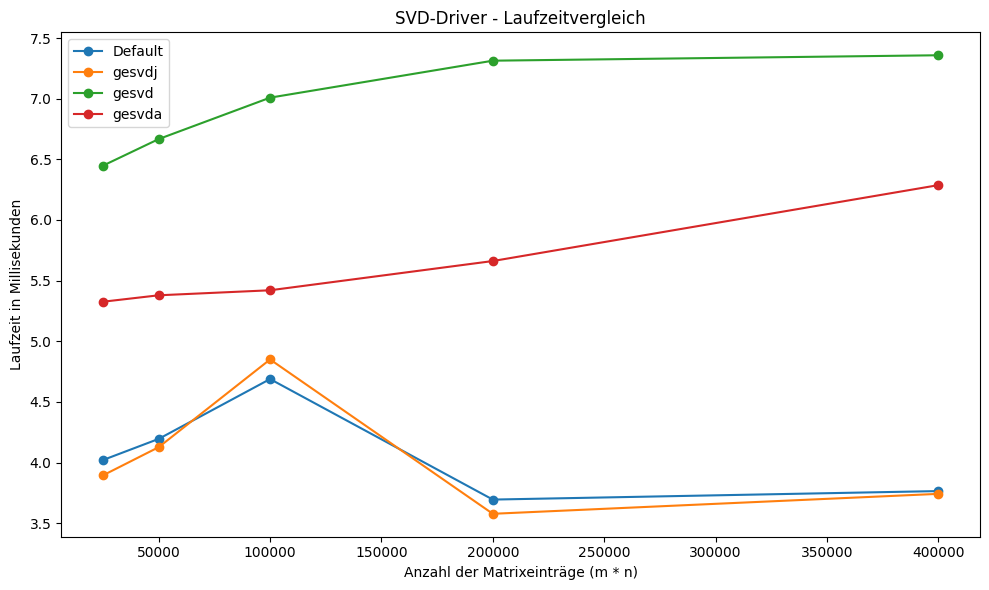

GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.004049581999993279, 0.003848610999995117, 0.003836754999980485, 0.003824145999999473, 0.0038110880000203906, 0.003849658000007139, 0.0038476860000002944, 0.0038373080000155824, 0.0037740359999816064, 0.003776921999985916]
SVD GPU - Durchschnitt: 3.8455791999979283 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.00379144100000417, 0.0038214090000110446, 0.003818049000017254, 0.0038238310000053843, 0.0038128009999809365, 0.0038493579999965277, 0.003780511000002207, 0.003815897000009727, 0.00380087499999604, 0.0037802580000061425]
SVD GPU - Durchschnitt: 3.8094430000029433 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.006096435000017664, 0.006571876999998949, 0.006577352999983077, 0.006353714999988824, 0.006197388000003912, 0.006294714000006252, 0.006347608999988097, 0.007489444000015055, 0.007357266000013851, 0.009214552000003096]
SVD GPU - Durchschnitt: 6.850035300001878 ms
GPU - Datentyp: torch.flo

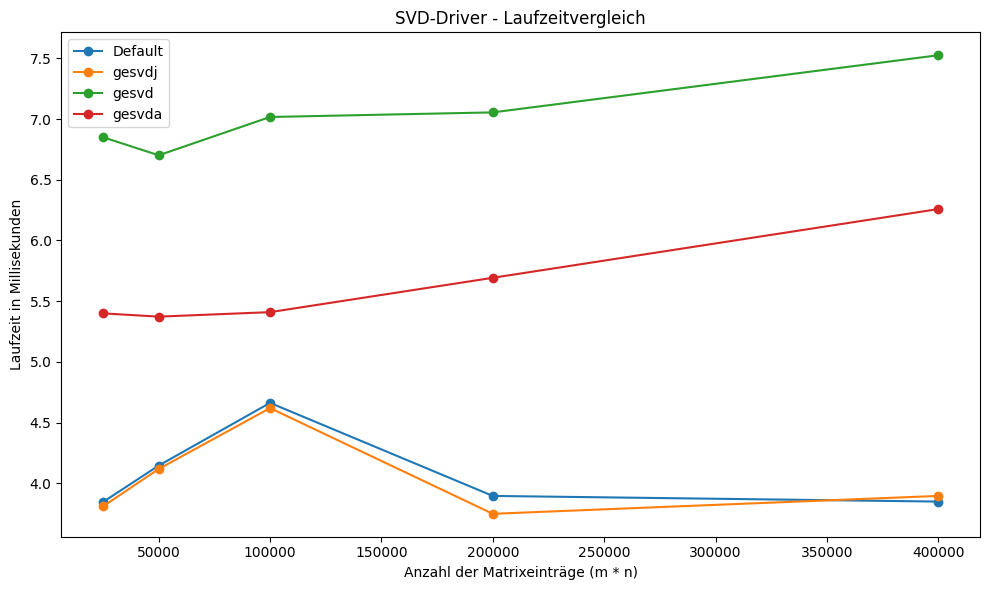

In [8]:
# Funktion 09
# Überspringen!!!
# die 4 verschiedenen SVD Driver vergleichen
# Andere Konfigurationen werden auf eine bestimmte Konfiguration festgesetzt
# Für jede Matrixgröße ein Balkendiagramm

# Funktion zum Vergleichen der SVD-Driver

def compare_drivers(matrix_sizes, diagram="both"):

    # Prüfen, ob eine CUDA-GPU verfügbar ist
    if torch.cuda.is_available() == False:
        print("Keine CUDA-GPU verfügbar")
        return

    # Verschiedene Driver festlegen
    drivers = [None, "gesvdj", "gesvd", "gesvda"]

    # Leere Listen für das Liniendiagramm erstellen
    matrix_sizes_x = []

    default_times = []
    gesvdj_times = []
    gesvd_times = []
    gesvda_times = []

    # Verschiedene Matrixgrößen durchlaufen
    for m, n in matrix_sizes:

        # Anzahl der Matrixeinträge speichern
        matrix_sizes_x.append(m * n)

        # Leere Listen für das Balkendiagramm erstellen
        names = []
        times = []

        # Verschiedene Driver vergleichen
        for driver in drivers:

            # Laufzeit messen
            runtime = measure_runtime(
                m=m,
                n=n,
                dtype=torch.float32,
                method="svd",
                device="cuda",
                reduced=True,
                include_transfer=False,
                driver=driver
            )

            # Ergebnisse für das Balkendiagramm speichern
            if driver == None:
                names.append("Default")
            else:
                names.append(driver)

            times.append(runtime)

            # Ergebnisse für das Liniendiagramm speichern
            if driver == None:
                default_times.append(runtime)

            elif driver == "gesvdj":
                gesvdj_times.append(runtime)

            elif driver == "gesvd":
                gesvd_times.append(runtime)

            elif driver == "gesvda":
                gesvda_times.append(runtime)

        # Balkendiagramm nur bei Bedarf erstellen
        if diagram == "bar" or diagram == "both":

            plt.figure(figsize=(10, 5))
            plt.barh(names, times)

            # Diagramm beschriften
            plt.title("SVD-Driver - Matrix " + str(m) + "x" + str(n))
            plt.xlabel("Laufzeit in Millisekunden")
            plt.ylabel("Driver")

            # Diagramm anzeigen
            plt.tight_layout()
            plt.show()

    # Liniendiagramm nur bei Bedarf erstellen
    if diagram == "line" or diagram == "both":

        plt.figure(figsize=(10, 6))

        # Laufzeitkurven der Driver zeichnen
        plt.plot(
            matrix_sizes_x,
            default_times,
            marker="o",
            label="Default"
        )

        plt.plot(
            matrix_sizes_x,
            gesvdj_times,
            marker="o",
            label="gesvdj"
        )

        plt.plot(
            matrix_sizes_x,
            gesvd_times,
            marker="o",
            label="gesvd"
        )

        plt.plot(
            matrix_sizes_x,
            gesvda_times,
            marker="o",
            label="gesvda"
        )

        # Diagramm beschriften
        plt.title("SVD-Driver - Laufzeitvergleich")
        plt.xlabel("Anzahl der Matrixeinträge (m * n)")
        plt.ylabel("Laufzeit in Millisekunden")
        plt.legend()

        # Diagramm anzeigen
        plt.tight_layout()
        plt.show()


# Drei einzelne Matrixformen vergleichen
# Nur Balkendiagramme erstellen
compare_drivers(
    [
        (1000, 1000),
        (5000, 200),
        (200, 5000)
    ],
    diagram="bar"
)


# Quadratische Matrizen untersuchen
# Nur Liniendiagramm erstellen
compare_drivers(
    square_matrices(),
    diagram="line"
)


# Hohe und schmale Matrizen untersuchen
# Nur Liniendiagramm erstellen
compare_drivers(
    tall_matrices(),
    diagram="line"
)


# Breite und flache Matrizen untersuchen
# Nur Liniendiagramm erstellen
compare_drivers(
    wide_matrices(),
    diagram="line"
)



# Anmerkungen: gesvda ist approximativ
# Falls wir den nehmen, evtl. Genauigkeit überprüfen

SVD CPU - Alle Messungen: [0.4833729580000181, 0.4282573159999856, 0.44797761600000285, 0.4282487139999773, 0.44377060800002255, 0.4478114590000075, 0.4650171240000134, 0.550270936000004, 0.5238587199999927, 0.5259478549999699]
SVD CPU - Durchschnitt: 474.4533305999994 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.16980304199995544, 0.17131414799996492, 0.17090663799996264, 0.17190895499999215, 0.17123716700001523, 0.1719934430000194, 0.17203316799998447, 0.1714930119999849, 0.17116879599996082, 0.17233981599997605]
SVD GPU - Durchschnitt: 171.4198184999816 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.17100636200001418, 0.17195625900001232, 0.17090478899996242, 0.1721492830000102, 0.17134267699998418, 0.17065928099998473, 0.1719172100000037, 0.17227683599998045, 0.1709697530000085, 0.1720727629999601]
SVD GPU - Durchschnitt: 171.52552129999208 ms
SVD CPU - Alle Messungen: [0.604962238999974, 0.5422838279999951, 0.5518468399999961, 0.5517880289999653, 0.

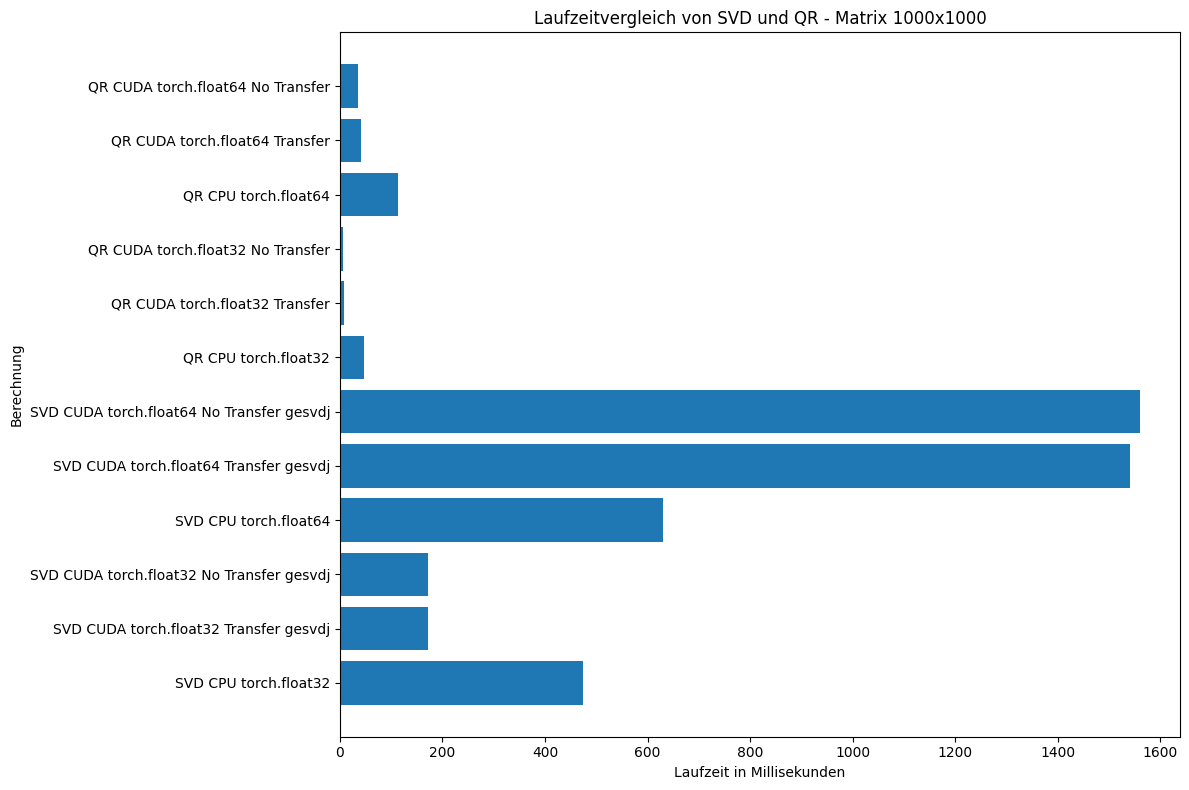

SVD CPU - Alle Messungen: [0.047755597000048056, 0.04424052600001005, 0.04428222500001766, 0.0429995819999931, 0.04370072899996558, 0.04373757299998715, 0.043129867999994076, 0.04319821100000354, 0.04433083399999305, 0.04651228199998059]
SVD CPU - Durchschnitt: 44.388742699999284 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.010383450999995603, 0.010333855999988373, 0.010346392000030846, 0.010318860999973367, 0.010307117000024846, 0.010364886999980172, 0.01041954900000519, 0.01030021700000816, 0.010352909000005184, 0.010294796000039241]
SVD GPU - Durchschnitt: 10.342203500005098 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.009431938000034279, 0.009421036999981425, 0.00942780700000867, 0.009477344000003995, 0.009458494999989853, 0.009427700999992794, 0.009557059999963258, 0.009516722000000755, 0.009440325000014127, 0.009432403999994676]
SVD GPU - Durchschnitt: 9.459083299998383 ms
SVD CPU - Alle Messungen: [0.07443408599999657, 0.08352802600001041, 0.077

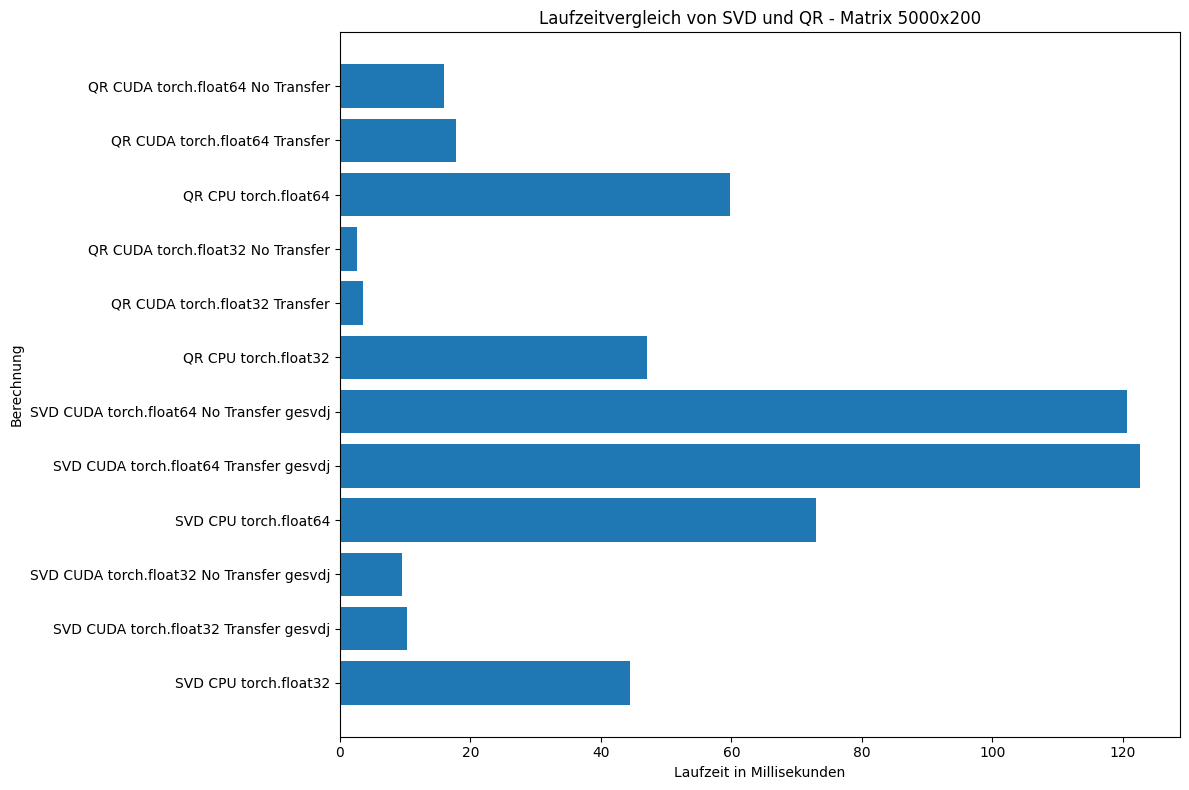

SVD CPU - Alle Messungen: [0.09116702700003998, 0.09425034899999218, 0.099673015999997, 0.09032094799999868, 0.09267294699998274, 0.09007450400002881, 0.09033632599999919, 0.08939708200000496, 0.09095052300000361, 0.08877138700000842]
SVD CPU - Durchschnitt: 91.76141090000556 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.010263779000013074, 0.010407680000014352, 0.010358581999980743, 0.010417221000011523, 0.010413836999987325, 0.010171022000008634, 0.010071886999980961, 0.010068282999952771, 0.010068391999993764, 0.01004491600002666]
SVD GPU - Durchschnitt: 10.22855989999698 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.009193791000029705, 0.009178695999992215, 0.00935540799997625, 0.00918938999996044, 0.00914416299997356, 0.00914757800001098, 0.009168998000006923, 0.009277147000034347, 0.009288027999957649, 0.009205278000024464]
SVD GPU - Durchschnitt: 9.214847699996653 ms
SVD CPU - Alle Messungen: [0.12023538699997971, 0.1147998799999641, 0.12117992399

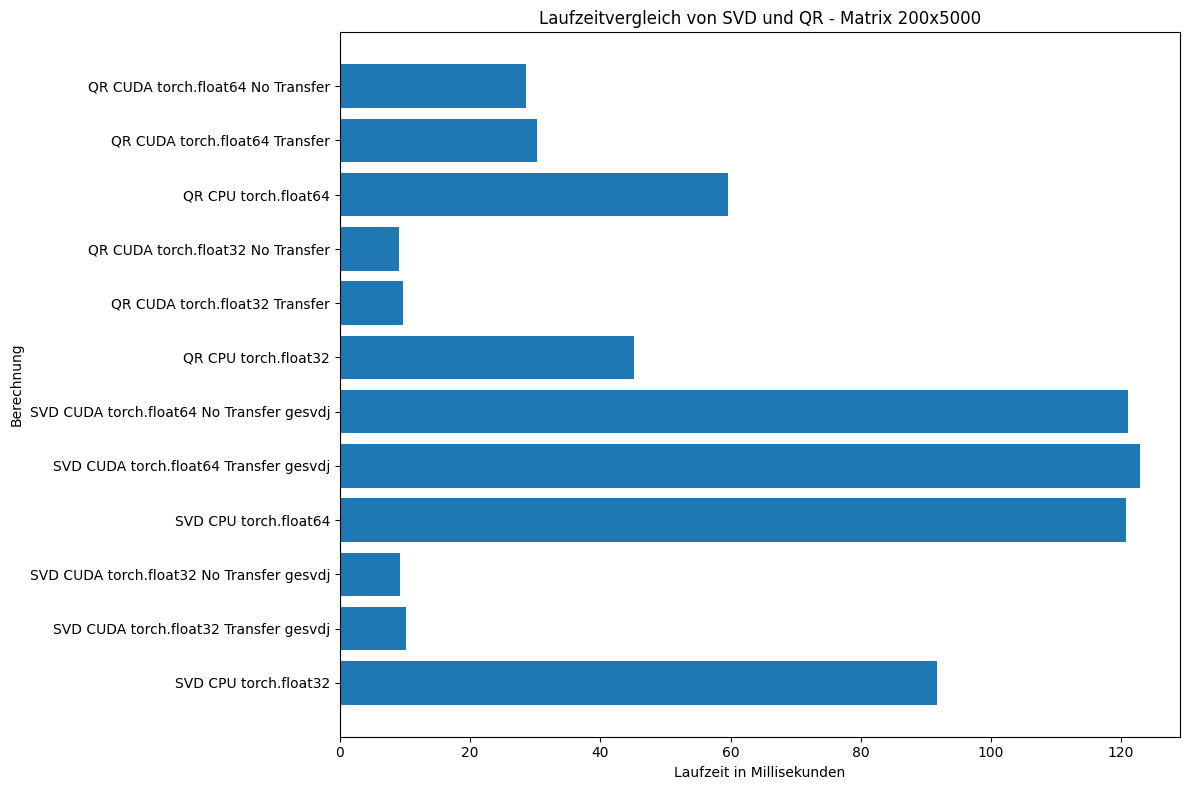

(['SVD CPU torch.float32',
  'SVD CUDA torch.float32 Transfer gesvdj',
  'SVD CUDA torch.float32 No Transfer gesvdj',
  'SVD CPU torch.float64',
  'SVD CUDA torch.float64 Transfer gesvdj',
  'SVD CUDA torch.float64 No Transfer gesvdj',
  'QR CPU torch.float32',
  'QR CUDA torch.float32 Transfer',
  'QR CUDA torch.float32 No Transfer',
  'QR CPU torch.float64',
  'QR CUDA torch.float64 Transfer',
  'QR CUDA torch.float64 No Transfer'],
 [91.76141090000556,
  10.22855989999698,
  9.214847699996653,
  120.68795059998934,
  122.90290459999369,
  121.01229200000603,
  45.103889900002514,
  9.760247900004515,
  9.11165550000419,
  59.59720610000545,
  30.317362100004175,
  28.59436569999616])

In [9]:
# Funktion 08
# Feste Matrixgröße, verschiedene Konfigurationen
# compare_runtimes neu aufgesetzt
# Funktion zum Vergleichen aller Laufzeiten

def compare_runtimes(m, n, driver="gesvd"):

    # Leere Listen für die Ergebnisse
    names = []
    times = []

    # Verfügbare Geräte
    devices = ["cpu"]

    # Prüfen, ob eine CUDA-GPU verfügbar ist
    if torch.cuda.is_available() == True:
        devices.append("cuda")

    # SVD und QR vergleichen
    for method in ["svd", "qr"]:

        # Float32 und Float64 vergleichen
        for dtype in [torch.float32, torch.float64]:

            # CPU und GPU vergleichen
            for device in devices:

                # Nur reduzierte Zerlegungen verwenden
                reduced = True

                # Datentransfer für CPU festlegen
                transfers = [False]

                # Bei GPU beide Möglichkeiten vergleichen
                if device == "cuda":
                    transfers = [True, False]

                # Mit und ohne Datentransfer vergleichen
                for include_transfer in transfers:

                    # Laufzeit messen
                    runtime = measure_runtime(
                        m=m,
                        n=n,
                        dtype=dtype,
                        method=method,
                        device=device,
                        reduced=reduced,
                        include_transfer=include_transfer,
                        driver=driver
                    )

                    # Beschriftung erstellen
                    name = (
                        method.upper() + " " +
                        device.upper() + " " +
                        str(dtype)
                    )

                    # Datentransfer bei GPU ergänzen
                    if device == "cuda":

                        if include_transfer == True:
                            name = name + " Transfer"

                        else:
                            name = name + " No Transfer"

                    # Driver bei GPU-SVD ergänzen
                    if device == "cuda" and method == "svd":

                        if driver == None:
                            name = name + " Default"

                        else:
                            name = name + " " + driver

                    # Ergebnisse in Listen speichern
                    names.append(name)
                    times.append(runtime)

    # Anzahl der Ergebnisse ausgeben
    print("Anzahl der Ergebnisse:", len(times))

    # Waagerechtes Balkendiagramm erstellen
    plt.figure(figsize=(12, 8))
    plt.barh(names, times)

    # Diagramm beschriften
    plt.title(
        "Laufzeitvergleich von SVD und QR - Matrix " +
        str(m) + "x" + str(n)
    )

    plt.xlabel("Laufzeit in Millisekunden")
    plt.ylabel("Berechnung")

    # Diagramm anzeigen
    plt.tight_layout()
    plt.show()

    return names, times

# Die 3 Matrixformen vergleichen - Driver später anpassen

# Quadratische Matrix vergleichen
compare_runtimes(
    m=1000,
    n=1000,
    driver="gesvd"
)

# Hohe und schmale Matrix vergleichen
compare_runtimes(
    m=5000,
    n=200,
    driver="gesvd"
)

# Breite und flache Matrix vergleichen
compare_runtimes(
    m=200,
    n=5000,
    driver="gesvd"
)

# Matrizen mit ca. derselben Anzahl an Einträgen nehmen
# 1000x1000, 5000x200, 200x5000

QR CPU - Alle Messungen: [0.0006895500000041466, 0.0016239010000163034, 0.0006250820000559543, 0.0004412569999772131, 0.00044577099998832637, 0.00043454500001871565, 0.0003827719999662804, 0.00044995499996502986, 0.00037735899996960143, 0.00042254900000671114]
QR CPU - Durchschnitt: 0.5892740999968282 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0012471740000137288, 0.0013718980000021475, 0.0012848160000089592, 0.0012779609999711283, 0.001288735999992241, 0.0012552460000279098, 0.0013076490000116792, 0.001284024000028694, 0.0012843650000036178, 0.0012493579999954818]
QR GPU - Durchschnitt: 1.2851227000055587 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0013027539999939108, 0.0013917530000071565, 0.00129233400002704, 0.0012856540000143468, 0.0012805769999886252, 0.001280490999988615, 0.0012818030000403269, 0.001276960999973653, 0.0012656800000172552, 0.0012594299999477698]
QR GPU - Durchschnitt: 1.29174369999987 ms
QR CPU - Alle Messungen: [0.001794625000

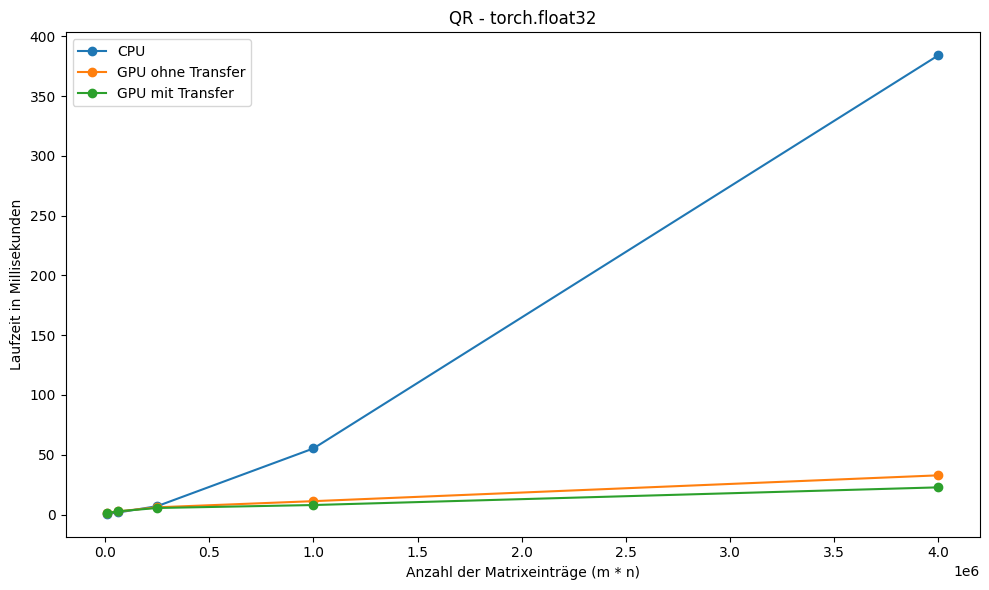

QR CPU - Alle Messungen: [0.0006173069999704239, 0.0006008959999803665, 0.0006781079999882422, 0.0006182170000101905, 0.0005476459999727012, 0.0006208009999681963, 0.0005624340000167649, 0.0005499799999597599, 0.0005814299999542527, 0.0005133459999910883]
QR CPU - Durchschnitt: 0.5890164999811986 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.0031144579999704547, 0.0030955819999576306, 0.0030967820000000756, 0.003087842000013552, 0.0030852399999616864, 0.003090688999975555, 0.0030906110000046283, 0.0030829199999971024, 0.003083455000023605, 0.0030959860000052686]
QR GPU - Durchschnitt: 3.092356499990956 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.0031555209999964973, 0.003141525999978967, 0.003143129000022782, 0.0031491839999944204, 0.003146187000027112, 0.0031389000000103806, 0.0031253240000523874, 0.003135622999991483, 0.0031342030000018894, 0.0031274199999984376]
QR GPU - Durchschnitt: 3.1397017000074356 ms
QR CPU - Alle Messungen: [0.00227250899996533

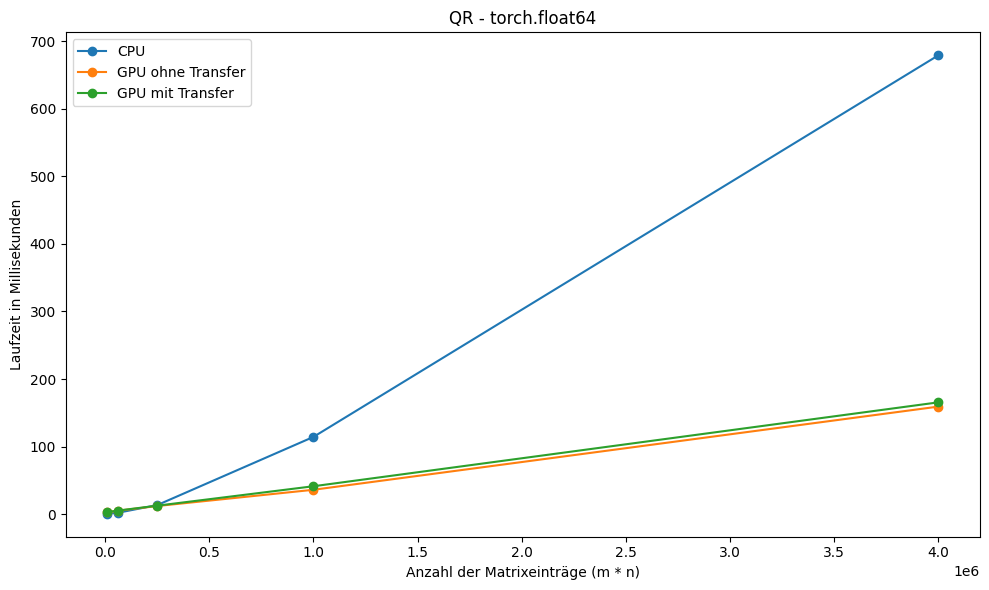

SVD CPU - Alle Messungen: [0.0025203519999763557, 0.004477147999978115, 0.004500698000015291, 0.004362835999984327, 0.002379776999987371, 0.002409775999979047, 0.0029863359999922068, 0.0024331399999937275, 0.002731132000008074, 0.00237902999998596]
SVD CPU - Durchschnitt: 3.1180224999900474 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.007456436999973448, 0.007583218999968722, 0.007768698999996104, 0.007511880000038218, 0.007352652000008675, 0.007239936999951624, 0.007179282000038256, 0.007182670999952734, 0.007216556999992463, 0.00720122099994569]
SVD GPU - Durchschnitt: 7.369255499986593 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.007536364999964462, 0.007203838000009455, 0.0071782449999773235, 0.007238687999972626, 0.007329570000024432, 0.007301493999989361, 0.007704208999996354, 0.008091358999990916, 0.008029028999999355, 0.008337302000029467]
SVD GPU - Durchschnitt: 7.595009899995375 ms
SVD CPU - Alle Messungen: [0.01246467099997517, 0.01237991900

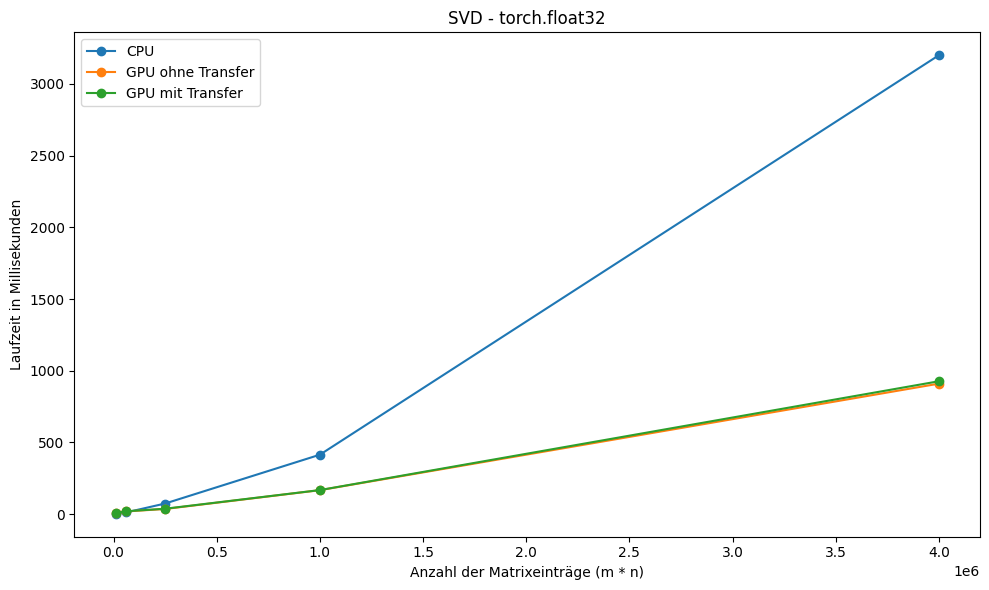

SVD CPU - Alle Messungen: [0.0046011289999796645, 0.003882848000046124, 0.005143250000003263, 0.0029301980000013828, 0.002974246000007952, 0.003116099999999733, 0.002978773000052115, 0.003006294000044818, 0.003149862000043413, 0.0034960940000132723]
SVD CPU - Durchschnitt: 3.5278794000191738 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.010990022999976645, 0.010064551999960258, 0.009558561000005739, 0.010029550000012932, 0.010313869000015075, 0.01071605799995723, 0.009677560000000085, 0.009905120000041734, 0.00998966500003462, 0.010236114000008456]
SVD GPU - Durchschnitt: 10.148107200001277 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.010104167999998026, 0.010092193999980736, 0.01163695100001405, 0.009908181000014338, 0.010026303000017833, 0.010074181999982557, 0.01020822399999588, 0.012072445000001153, 0.011528255000030185, 0.010605680000026041]
SVD GPU - Durchschnitt: 10.62565830000608 ms
SVD CPU - Alle Messungen: [0.01524455499998112, 0.0143839090000

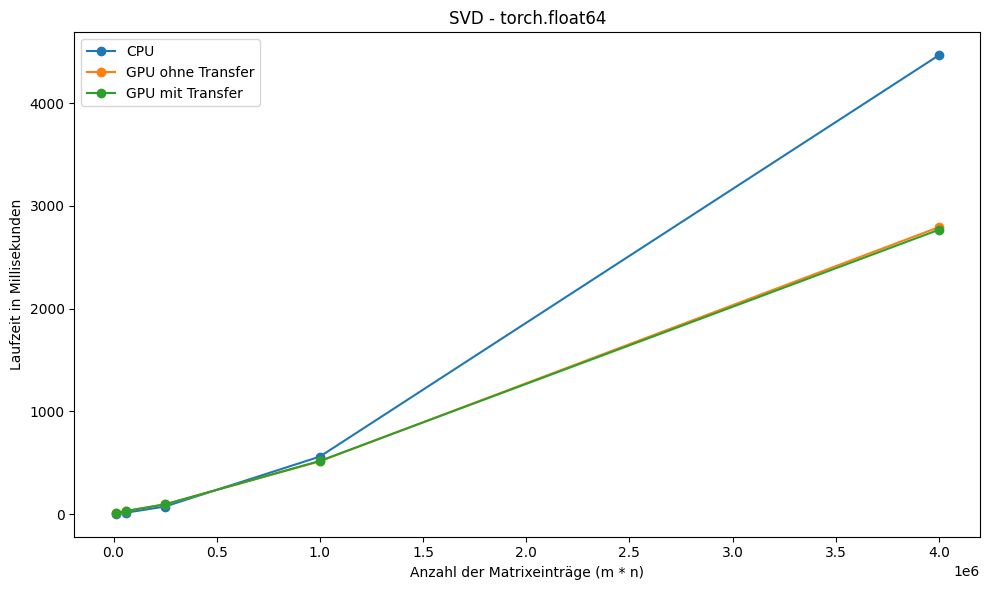

QR CPU - Alle Messungen: [0.0009650840000858807, 0.001016365000054975, 0.0009670760000517475, 0.0009329849999630824, 0.0009417329999905633, 0.0009494050000284915, 0.0009388119999584887, 0.0009175889999823994, 0.0009677959999407904, 0.0009277139999994688]
QR CPU - Durchschnitt: 0.9524559000055888 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0004693450000559096, 0.00045406899994304695, 0.0004586160000599193, 0.0004581140000254891, 0.000497139000003699, 0.000495417000024645, 0.0004694470000004003, 0.00044615399997383065, 0.0004432819999919957, 0.0004345349999539394]
QR GPU - Durchschnitt: 0.4626118000032875 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0005109759999868402, 0.000510420999944472, 0.0005036190000282659, 0.000525114000083704, 0.0005426640000223415, 0.0004950740000140286, 0.0005457010000782248, 0.0004928229999450195, 0.0004908649999606496, 0.0005156480000323427]
QR GPU - Durchschnitt: 0.5132905000095889 ms
QR CPU - Alle Messungen: [0.001105823999

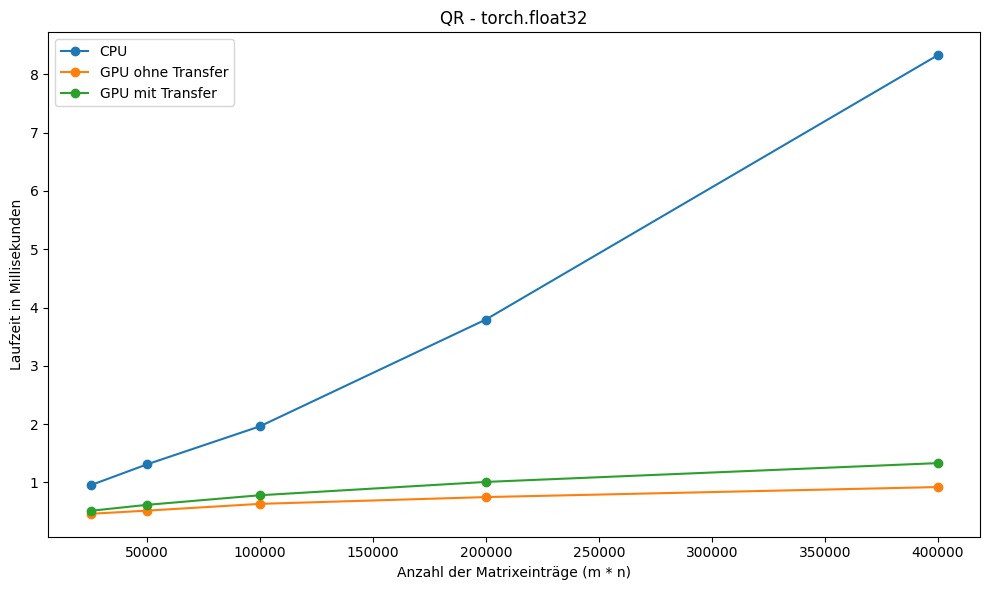

QR CPU - Alle Messungen: [0.0010636919998887606, 0.0010088089999271688, 0.0010088230000064868, 0.001045168000018748, 0.0009423850000302991, 0.0010489459999689643, 0.001077126000041062, 0.0009213000000727334, 0.0010628759999917747, 0.0011011459999963336]
QR CPU - Durchschnitt: 1.0280270999942331 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.002105142999994314, 0.0019733489999680387, 0.0019188539999959175, 0.001919607999980144, 0.0018962039999905755, 0.0019031860000495726, 0.0019010940000043774, 0.0019091249999974025, 0.0019025420000389204, 0.0018948860000591594]
QR GPU - Durchschnitt: 1.9323991000078422 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.001994500000023436, 0.0020077350000065053, 0.00207827899998847, 0.002000474999931612, 0.0019827460000669817, 0.0019853539999985514, 0.002000818000055915, 0.001987897999924826, 0.001995050999994419, 0.001981680000085362]
QR GPU - Durchschnitt: 2.0014536000076077 ms
QR CPU - Alle Messungen: [0.0013040510000337235, 

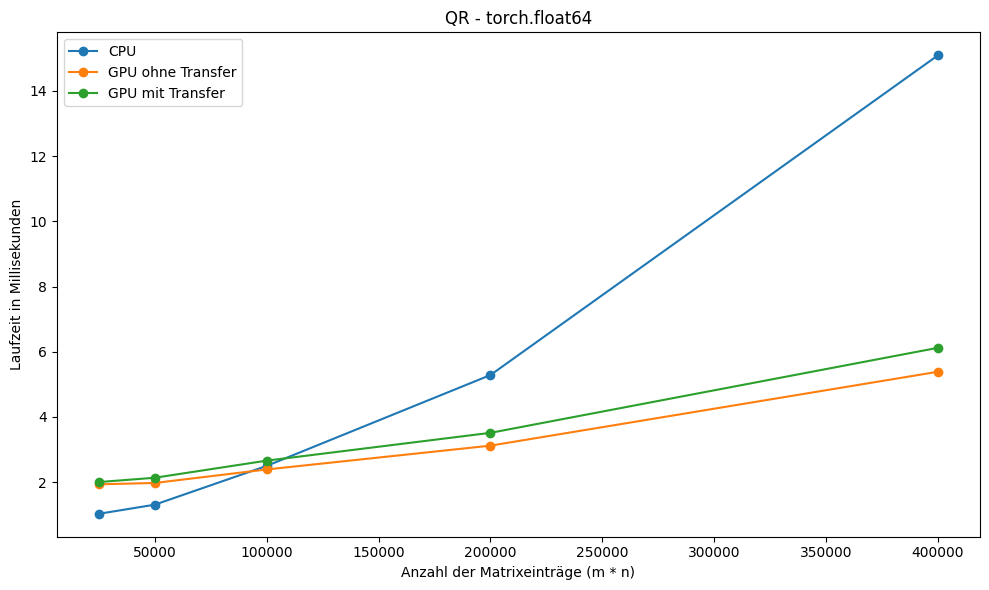

SVD CPU - Alle Messungen: [0.003733570999997937, 0.003799629000013738, 0.005624285000067175, 0.003533930000003238, 0.002837226999986342, 0.0027065019999099604, 0.0025362469999663517, 0.0025558499999078776, 0.0025211089999856995, 0.0023549609999236054]
SVD CPU - Durchschnitt: 3.2203310999761925 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.006281629000000066, 0.006404341999996177, 0.006450538000080996, 0.006536019000009219, 0.00662434100001974, 0.0062207150000404, 0.006408113000020421, 0.006664576000048328, 0.006367859999954817, 0.006246401999987938]
SVD GPU - Durchschnitt: 6.42045350001581 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.006286896999995406, 0.0065694429999894055, 0.006355242000040562, 0.006337080999969658, 0.0062549110000418295, 0.006249695000065003, 0.006497838999962369, 0.006468851000022369, 0.006387666000023273, 0.006403088000070056]
SVD GPU - Durchschnitt: 6.381071300017993 ms
SVD CPU - Alle Messungen: [0.0027599960000088686, 0.00312135

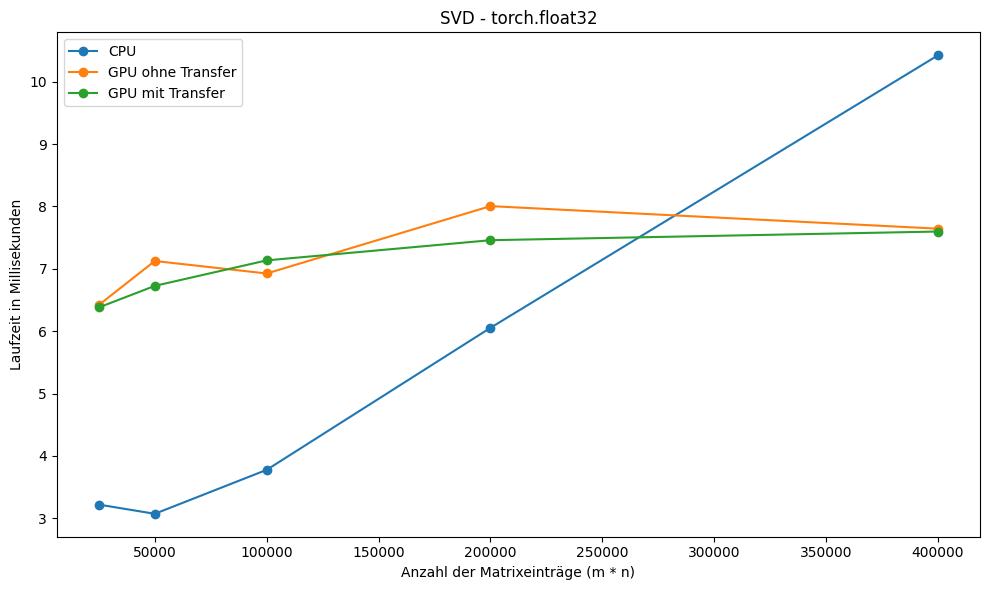

SVD CPU - Alle Messungen: [0.004309736999971392, 0.0032440510000242284, 0.003181170000061684, 0.0030789219999860507, 0.0030072689999087743, 0.0027633379999087992, 0.0029690999999729684, 0.0028416970000080255, 0.003369015999965086, 0.00327775699997801]
SVD CPU - Durchschnitt: 3.204205699978502 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.011962010000047485, 0.011840634999998656, 0.011916611999936322, 0.011789720000024317, 0.011788046999981816, 0.012198089000094114, 0.011788167999952748, 0.011801887000046918, 0.011804529000073671, 0.011763750999989497]
SVD GPU - Durchschnitt: 11.865344800014554 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.011885544999927333, 0.011866646999919794, 0.011846976000015275, 0.011892187999933412, 0.01356258499993146, 0.012670054000068376, 0.011858499000027223, 0.011856999999963591, 0.011883832000080474, 0.011869800999988911]
SVD GPU - Durchschnitt: 12.119312699985585 ms
SVD CPU - Alle Messungen: [0.004007411999964461, 0.0038667

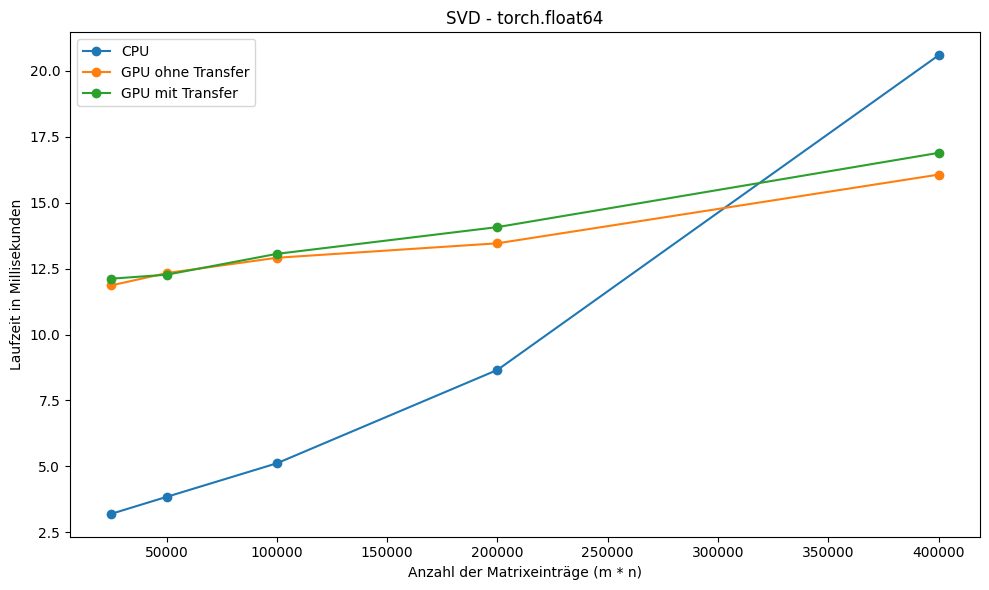

QR CPU - Alle Messungen: [0.0012063379999744939, 0.001260926999975709, 0.0012990630000331294, 0.0012569560000201818, 0.0011946250000391956, 0.0013219080000226313, 0.0013011350000624589, 0.001314308000019082, 0.001309108000100423, 0.0013601130000324702]
QR CPU - Durchschnitt: 1.2824481000279775 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0007250419999991209, 0.0006391739999571655, 0.0006552529999908074, 0.0007327609999947526, 0.0006801929999937784, 0.0006930719999900248, 0.0006935330000032991, 0.0006441889998995975, 0.0006580409999514814, 0.0007519789999150817]
QR GPU - Durchschnitt: 0.6873236999695109 ms
GPU - Datentyp: torch.float32
QR GPU - Alle Messungen: [0.0009646820000170919, 0.0008446200000662429, 0.0010810069999251937, 0.000738636000050974, 0.0006452129999843237, 0.0006131320000122287, 0.000670721999995294, 0.0005974319999495492, 0.0006134369999699629, 0.0006654919999391495]
QR GPU - Durchschnitt: 0.743437299991001 ms
QR CPU - Alle Messungen: [0.001809711999953

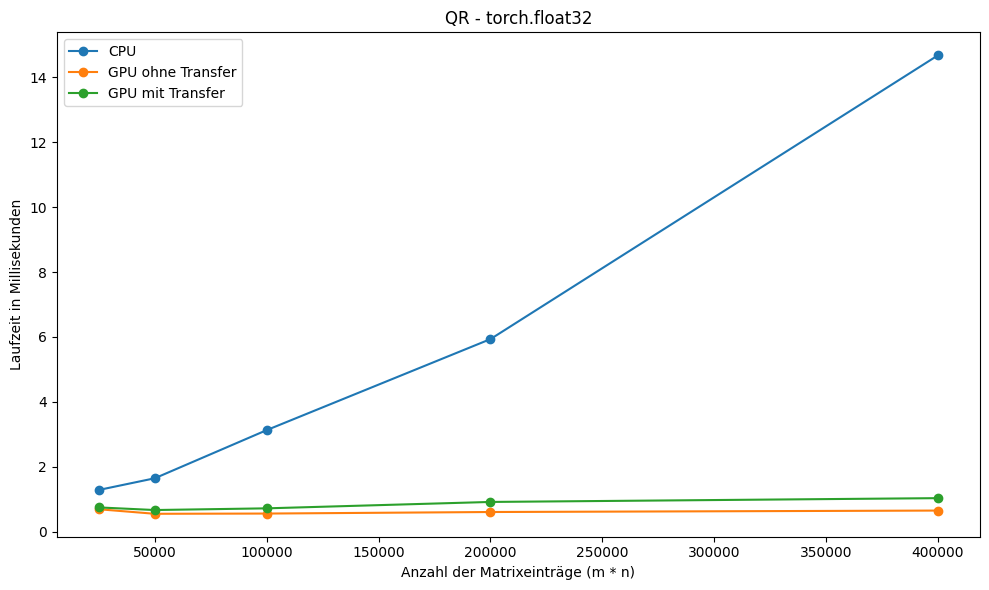

QR CPU - Alle Messungen: [0.0009823279999636725, 0.000919210999995812, 0.001009558999953697, 0.0010106160000304953, 0.001039888999912364, 0.0009186749999798849, 0.0009345920000214392, 0.0010381840000945886, 0.000990598000043974, 0.0009991970000555739]
QR CPU - Durchschnitt: 0.98428490000515 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.0033495849999098937, 0.0032974669999248363, 0.003334801000050902, 0.00330311499999425, 0.003265920999979244, 0.0032672249999450287, 0.0032616180000104578, 0.003255919000025642, 0.003258974000004855, 0.0032468260000086957]
QR GPU - Durchschnitt: 3.2841450999853805 ms
GPU - Datentyp: torch.float64
QR GPU - Alle Messungen: [0.003364835999946081, 0.0033477950000815326, 0.0033435840000493044, 0.0033315460000267194, 0.003329730999894309, 0.0033356349999849044, 0.0033334000000877495, 0.0033494099999415994, 0.0033995490000506834, 0.003358759999969152]
QR GPU - Durchschnitt: 3.3494246000032035 ms
QR CPU - Alle Messungen: [0.0011570340000162105, 0.0

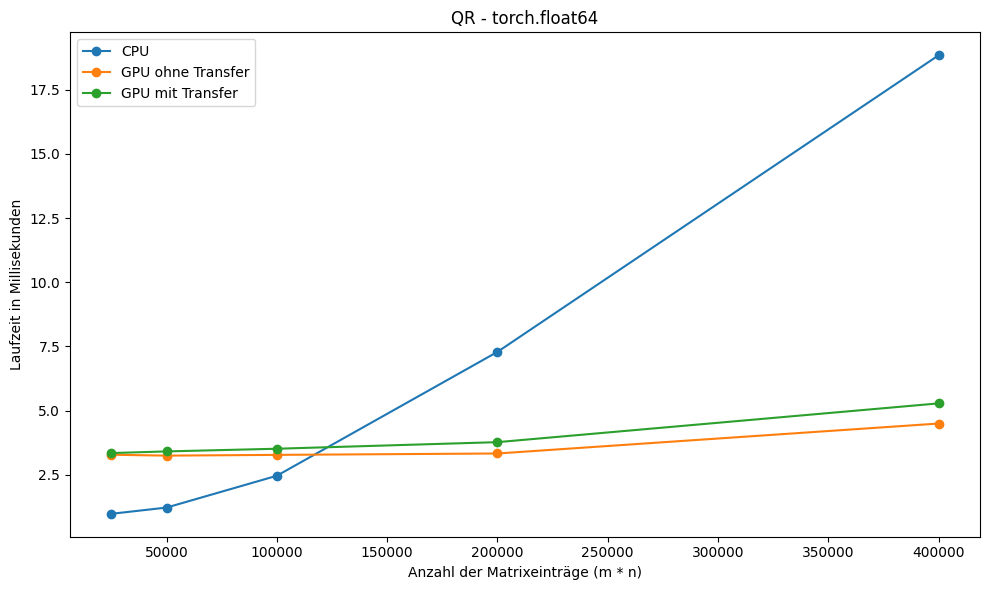

SVD CPU - Alle Messungen: [0.0044289459999617975, 0.003781714999945507, 0.004079853999996885, 0.003960243000051378, 0.00433786799999325, 0.003007016999958978, 0.0032428700000082245, 0.003058767999959855, 0.0029277630000024146, 0.0031454319999966174]
SVD CPU - Durchschnitt: 3.5970475999874907 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.005896165999956793, 0.005941640000060033, 0.005883658000016112, 0.005891810999969493, 0.005972818000032021, 0.005904142999952455, 0.00617552500000329, 0.006021712000006119, 0.005928400000016154, 0.005888168000069527]
SVD GPU - Durchschnitt: 5.9504041000082 ms
GPU - Datentyp: torch.float32
SVD GPU - Alle Messungen: [0.006054371000004721, 0.006083049000039864, 0.0060003659999665615, 0.005946076999975958, 0.005959730999961721, 0.005919319999975414, 0.006070012000009228, 0.005917049000004226, 0.005939227999988361, 0.0059482399999524205]
SVD GPU - Durchschnitt: 5.983744299987848 ms
SVD CPU - Alle Messungen: [0.004570900999965488, 0.0049076860

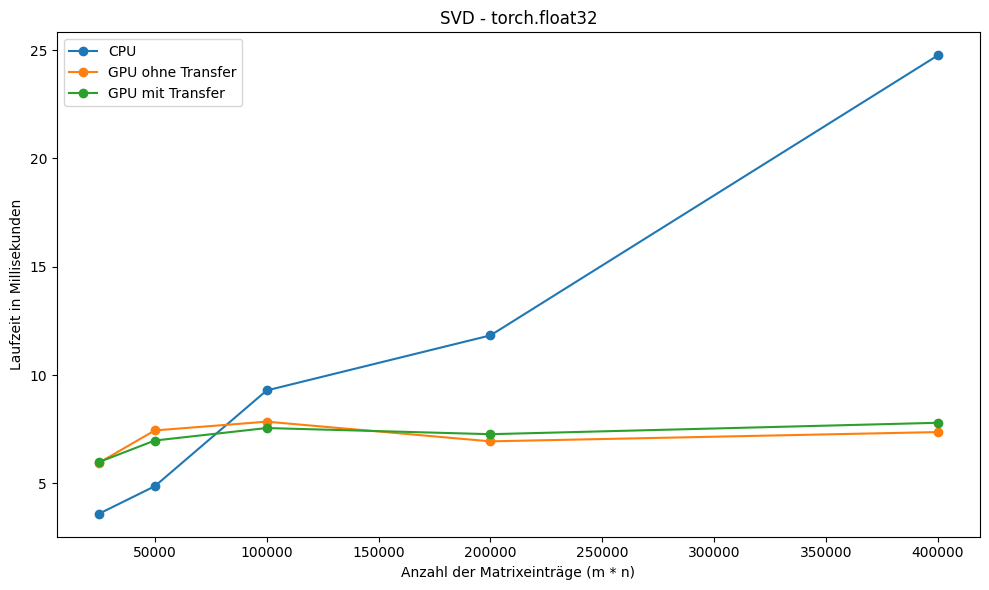

SVD CPU - Alle Messungen: [0.004190689000097336, 0.0041172309998955825, 0.004067813000006026, 0.004309034000016254, 0.003889126999979453, 0.003113361000032455, 0.0031670409999833282, 0.003129983999997421, 0.003024754999955803, 0.003223261999892202]
SVD CPU - Durchschnitt: 3.623229699985586 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.01149808299999222, 0.011486792999903628, 0.011481175999961124, 0.011504621999961273, 0.01288147000002482, 0.012626017999991745, 0.011568994000072053, 0.011472773000036796, 0.011529978999988089, 0.011516624000023512]
SVD GPU - Durchschnitt: 11.756653199995526 ms
GPU - Datentyp: torch.float64
SVD GPU - Alle Messungen: [0.011631411999928787, 0.011597100000017235, 0.011578794000001835, 0.012353401000041231, 0.013000720000036381, 0.01165989800006173, 0.012501030000066748, 0.011634165999907964, 0.011562051000055362, 0.011586301000079402]
SVD GPU - Durchschnitt: 11.910487300019668 ms
SVD CPU - Alle Messungen: [0.004853621000052044, 0.004979142000

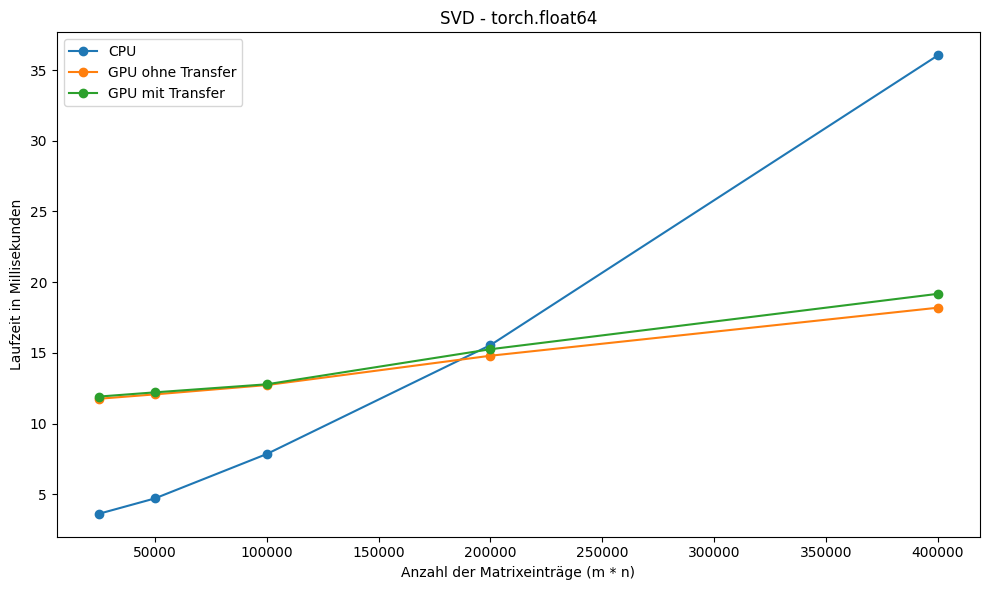

In [10]:
# Funktion 10
# Feste Konfiguration, verschiedene Matrixgrößen
# eine feste Konfiguration, mit der SVD auf GPU/CPU
# und QR auf GPU/CPU mit Liniendiagrammen verglichen wird
# 3 Linien: CPU, GPU mit Transfer, GPU ohne Transfer

def compare_configurations(matrix_sizes, method, dtype, driver="gesvd"):

    # Leere Listen für die Ergebnisse
    matrix_sizes_x = []

    cpu_times = []
    gpu_times = []
    gpu_transfer_times = []

    # Prüfen, ob eine CUDA-GPU verfügbar ist
    gpu_available = torch.cuda.is_available()

    # Verschiedene Matrixgrößen durchlaufen
    for m, n in matrix_sizes:

        # Anzahl der Matrixeinträge speichern
        matrix_sizes_x.append(m * n)

        # CPU-Laufzeit messen
        runtime = measure_runtime(
            m=m,
            n=n,
            dtype=dtype,
            method=method,
            device="cpu",
            reduced=True,
            include_transfer=False,
            driver=None
        )

        # CPU-Ergebnis speichern
        cpu_times.append(runtime)

        # GPU nur messen, wenn CUDA verfügbar ist
        if gpu_available == True:

            # GPU ohne Transfer messen
            runtime = measure_runtime(
                m=m,
                n=n,
                dtype=dtype,
                method=method,
                device="cuda",
                reduced=True,
                include_transfer=False,
                driver=driver
            )

            gpu_times.append(runtime)

            # GPU mit Transfer messen
            runtime = measure_runtime(
                m=m,
                n=n,
                dtype=dtype,
                method=method,
                device="cuda",
                reduced=True,
                include_transfer=True,
                driver=driver
            )

            gpu_transfer_times.append(runtime)

    # Liniendiagramm erstellen
    plt.figure(figsize=(10, 6))

    # CPU-Linie zeichnen
    plt.plot(matrix_sizes_x, cpu_times, marker="o", label="CPU")

    # GPU-Linien zeichnen
    if gpu_available == True:

        plt.plot(
            matrix_sizes_x,
            gpu_times,
            marker="o",
            label="GPU ohne Transfer"
        )

        plt.plot(
            matrix_sizes_x,
            gpu_transfer_times,
            marker="o",
            label="GPU mit Transfer"
        )

    # Diagramm beschriften
    plt.title(method.upper() + " - " + str(dtype))
    plt.xlabel("Anzahl der Matrixeinträge (m * n)")
    plt.ylabel("Laufzeit in Millisekunden")
    plt.legend()

    # Diagramm anzeigen
    plt.tight_layout()
    plt.show()

# Testfälle

######## Quadratisch ###############
# QR, Float32, quadratische Matrizen
compare_configurations(
    matrix_sizes=square_matrices(),
    method="qr",
    dtype=torch.float32
)

# QR, Float64, quadratische Matrizen
compare_configurations(
    matrix_sizes=square_matrices(),
    method="qr",
    dtype=torch.float64
)

# SVD, Float32, quadratische Matrizen
compare_configurations(
    matrix_sizes=square_matrices(),
    method="svd",
    dtype=torch.float32,
    driver="gesvd"
)

# SVD, Float64, quadratische Matrizen
compare_configurations(
    matrix_sizes=square_matrices(),
    method="svd",
    dtype=torch.float64,
    driver="gesvd"
)
###################################################

########## schmale ###############################
# QR, Float32, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=tall_matrices(),
    method="qr",
    dtype=torch.float32
)

# QR, Float64, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=tall_matrices(),
    method="qr",
    dtype=torch.float64
)

# SVD, Float32, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=tall_matrices(),
    method="svd",
    dtype=torch.float32,
    driver = "gesvd"
)

# SVD, Float64, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=tall_matrices(),
    method="svd",
    dtype=torch.float64,
    driver = "gesvd"
)
#########################################

########### breite #######################
# QR, Float32, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=wide_matrices(),
    method="qr",
    dtype=torch.float32
)

# QR, Float64, hohe/schmale Matrizen
compare_configurations(
    matrix_sizes=wide_matrices(),
    method="qr",
    dtype=torch.float64
)

# SVD, Float32, breite/flache Matrizen
compare_configurations(
    matrix_sizes=wide_matrices(),
    method="svd",
    dtype=torch.float32,
    driver="gesvd"
)

# SVD, Float64, breite/flache Matrizen
compare_configurations(
    matrix_sizes=wide_matrices(),
    method="svd",
    dtype=torch.float64,
    driver="gesvd"
)
#################################################